# Hanoi Housing Price Drivers – Multiple Linear Regression

**Question:** What drives asking prices of houses in Hanoi, and by how much?

**Data:** 11,294 house listings in Hanoi (Jul–Aug 2020), source: Kaggle "VN housing dataset"
**Tools:** Python (pandas, scikit-learn, statsmodels, matplotlib, seaborn) · Google Colab

**Contents:** 1. Data cleaning · 2. Outliers · 3. EDA · 4. Encoding · 5. Model · 6. Evaluation · 7. Statistical tests · 8. Prediction · 9. Adding ward · 10. Conclusion

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = 'data/VN_housing_dataset.csv'
if not os.path.exists(DATA_PATH):
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/Colab Notebooks/VN_housing_dataset.csv'

df = pd.read_csv(DATA_PATH)
print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(11294, 12)


## 1. Data overview

In [6]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11294 entries, 0 to 11293
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Ngày             11294 non-null  object 
 1   Địa chỉ          11294 non-null  object 
 2   Quận             11294 non-null  object 
 3   Phường           11294 non-null  object 
 4   Loại hình nhà ở  11294 non-null  object 
 5   Giấy tờ pháp lý  11294 non-null  object 
 6   Số tầng          11294 non-null  float64
 7   Số phòng ngủ     11294 non-null  object 
 8   Diện tích        11294 non-null  float64
 9   Dài              11294 non-null  object 
 10  Rộng             11294 non-null  object 
 11  Giá              11294 non-null  float64
dtypes: float64(3), object(9)
memory usage: 1.0+ MB


,Số tầng,Diện tích,Giá
count,11294.000000,11294.000000,11294.000000
mean,4.397291,47.617673,5.175339
std,1.817844,30.780440,5.997297
min,1.000000,1.000000,0.000000
25%,4.000000,33.000000,2.600070
50%,4.000000,40.000000,3.550080
75%,5.000000,51.000000,5.500000
max,73.000000,677.000000,99.999900


## 2. Data cleaning

In [7]:
df['Số phòng ngủ'] = df['Số phòng ngủ'].str.extract(r'(\d+)').astype(float)
df['Dài']  = df['Dài'].str.extract(r'(\d+\.?\d*)').astype(float)
df['Rộng'] = df['Rộng'].str.extract(r'(\d+\.?\d*)').astype(float)

In [8]:
df = df.drop(columns=['Ngày', 'Địa chỉ', 'Phường'])

In [9]:
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11294 entries, 0 to 11293
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Quận             11294 non-null  object 
 1   Loại hình nhà ở  11294 non-null  object 
 2   Giấy tờ pháp lý  11294 non-null  object 
 3   Số tầng          11294 non-null  float64
 4   Số phòng ngủ     11294 non-null  float64
 5   Diện tích        11294 non-null  float64
 6   Dài              11294 non-null  float64
 7   Rộng             11294 non-null  float64
 8   Giá              11294 non-null  float64
dtypes: float64(6), object(3)
memory usage: 794.2+ KB


,0
Quận,0
Loại hình nhà ở,0
Giấy tờ pháp lý,0
Số tầng,0
Số phòng ngủ,0
Diện tích,0
Dài,0
Rộng,0
Giá,0


## 3. Outliers

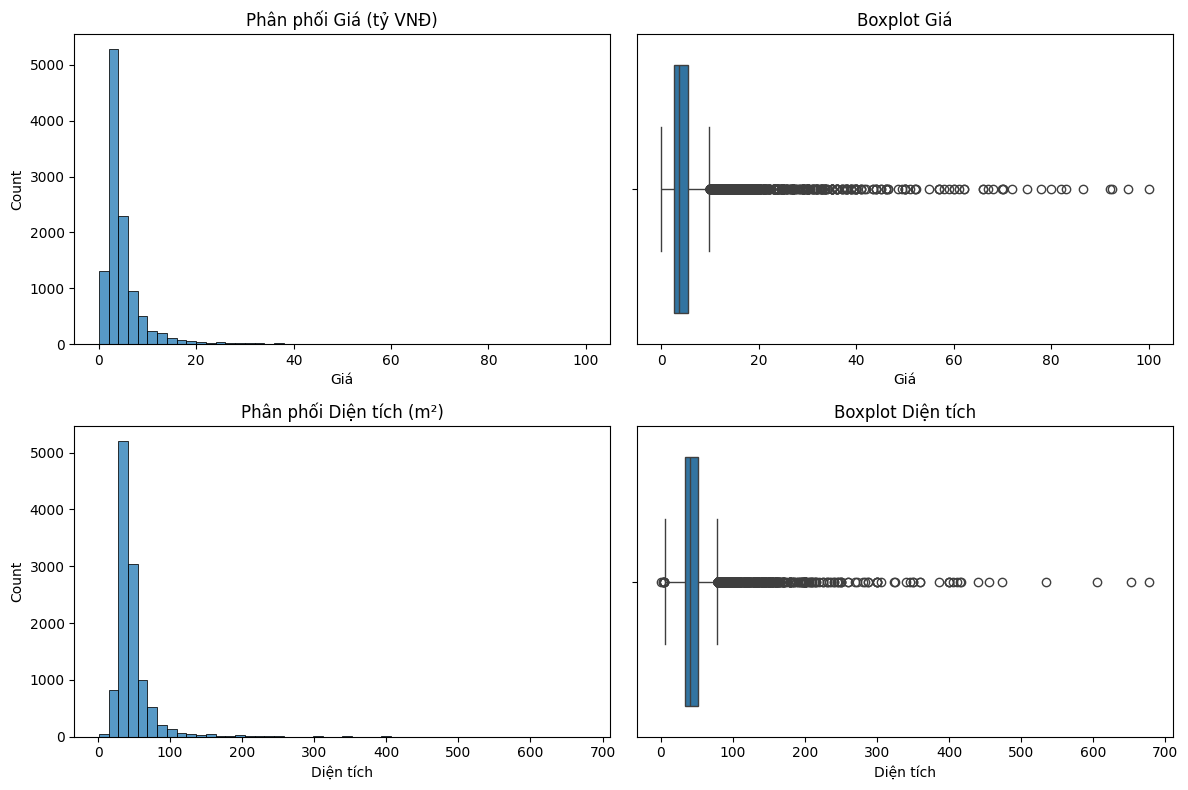

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['Giá'], bins=50, ax=ax[0,0])
ax[0,0].set_title('Phân phối Giá (tỷ VNĐ)')

sns.boxplot(x=df['Giá'], ax=ax[0,1])
ax[0,1].set_title('Boxplot Giá')

sns.histplot(df['Diện tích'], bins=50, ax=ax[1,0])
ax[1,0].set_title('Phân phối Diện tích (m²)')

sns.boxplot(x=df['Diện tích'], ax=ax[1,1])
ax[1,1].set_title('Boxplot Diện tích')

plt.tight_layout()
plt.show()

In [11]:
def remove_outliers(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    print(f'{col}: giữ trong [{lower:.2f}, {upper:.2f}]')
    return data[(data[col] >= lower) & (data[col] <= upper)]

df = df[df['Giá'] > 0]            # bỏ nhà giá 0
df = remove_outliers(df, 'Giá')
df = remove_outliers(df, 'Diện tích')
print('Còn lại:', df.shape)

Giá: giữ trong [-1.75, 9.85]
Diện tích: giữ trong [7.50, 75.50]
Còn lại: (9929, 9)


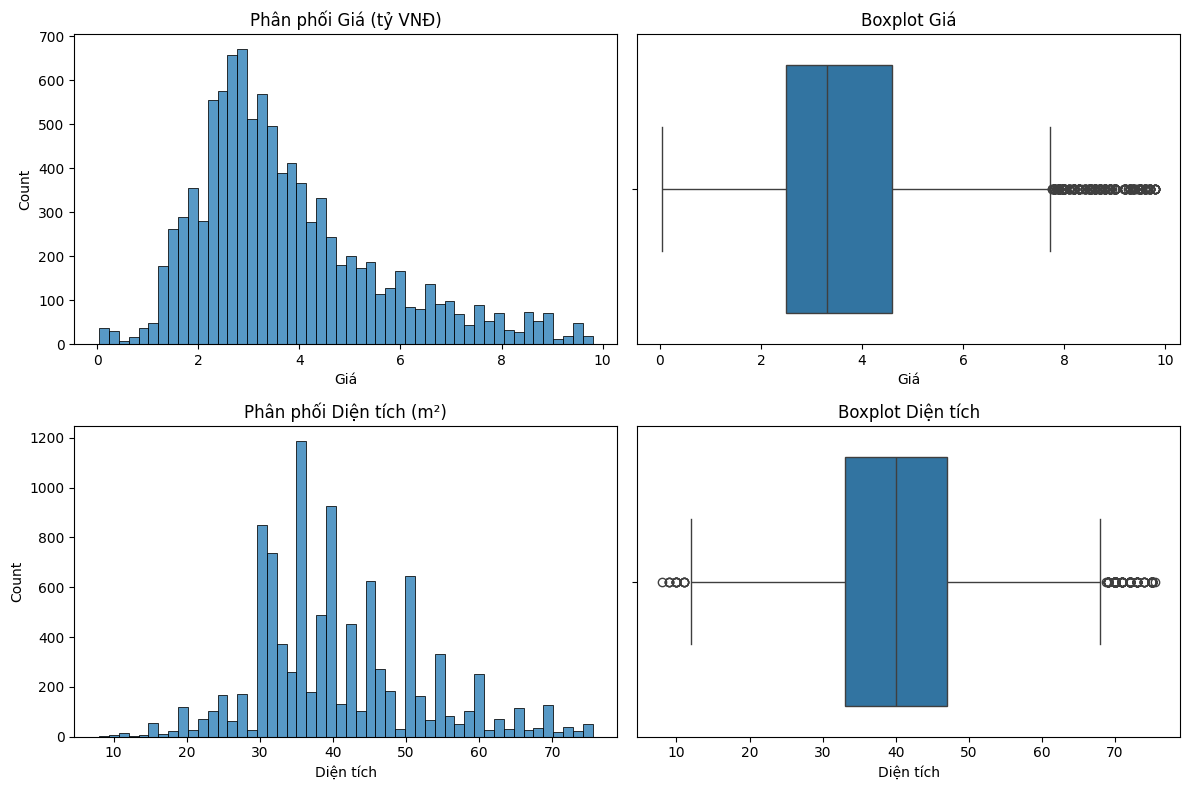

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['Giá'], bins=50, ax=ax[0,0])
ax[0,0].set_title('Phân phối Giá (tỷ VNĐ)')

sns.boxplot(x=df['Giá'], ax=ax[0,1])
ax[0,1].set_title('Boxplot Giá')

sns.histplot(df['Diện tích'], bins=50, ax=ax[1,0])
ax[1,0].set_title('Phân phối Diện tích (m²)')

sns.boxplot(x=df['Diện tích'], ax=ax[1,1])
ax[1,1].set_title('Boxplot Diện tích')

plt.tight_layout()
plt.show()

In [13]:
df = df[df['Giá'] >= 0.5]
print(df.shape)

(9862, 9)


## 4. EDA

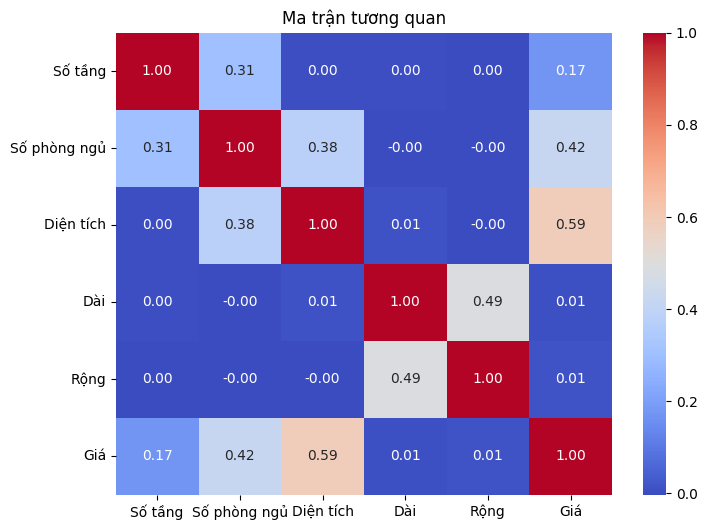

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Ma trận tương quan')
plt.show()

In [15]:
df[['Dài','Rộng']].describe()

,Dài,Rộng
count,9862.000000,9862.000000
mean,46.360011,17.184474
std,1308.238473,198.543355
min,1.000000,1.000000
25%,8.000000,3.500000
50%,10.000000,4.000000
75%,11.000000,5.000000
max,120000.000000,5500.000000


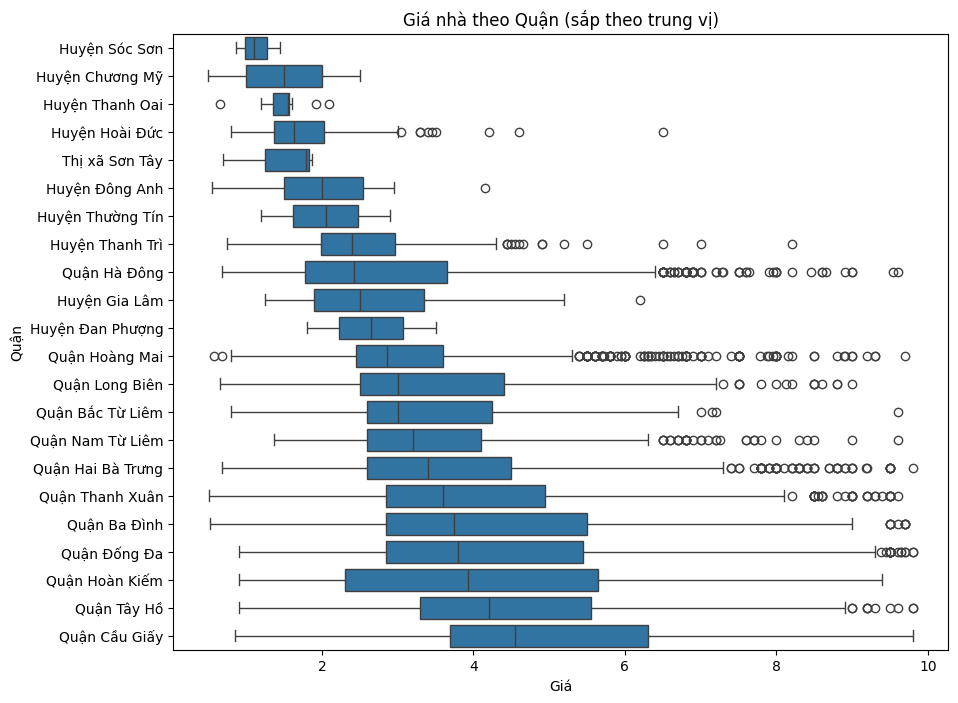

,count
Quận,
Quận Hà Đông,1465
Quận Đống Đa,1356
Quận Thanh Xuân,1303
Quận Hoàng Mai,1158
Quận Hai Bà Trưng,927
Quận Cầu Giấy,894
Quận Long Biên,650
Quận Ba Đình,549
Quận Nam Từ Liêm,465


In [16]:
order = df.groupby('Quận')['Giá'].median().sort_values().index
plt.figure(figsize=(10, 8))
sns.boxplot(data=df, y='Quận', x='Giá', order=order)
plt.title('Giá nhà theo Quận (sắp theo trung vị)')
plt.show()

df['Quận'].value_counts()

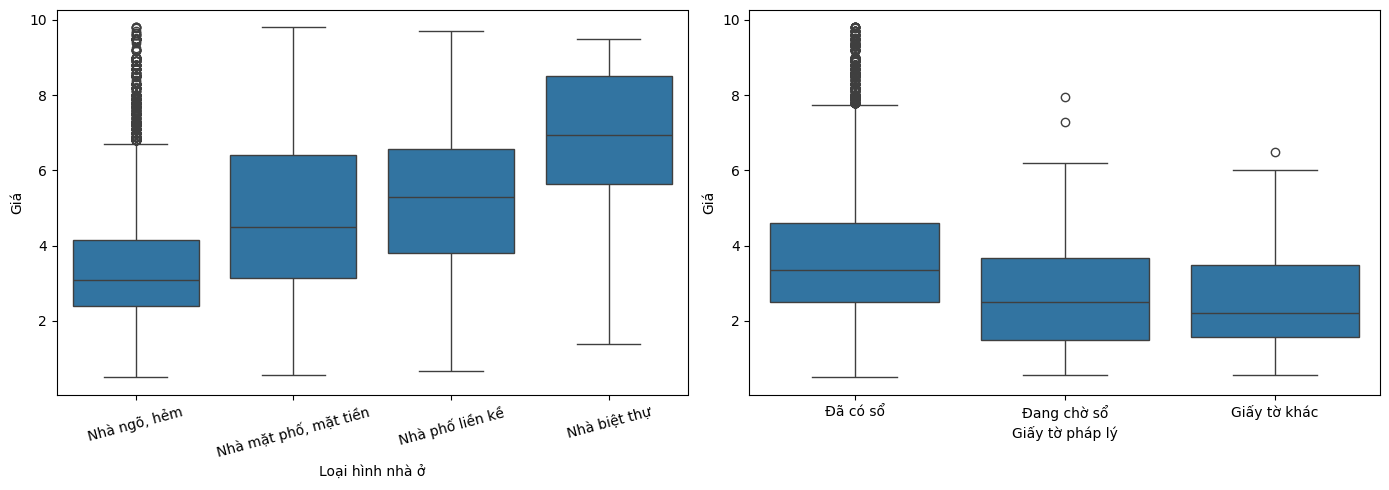

Giấy tờ pháp lý
Đã có sổ        0.987731
Đang chờ sổ     0.006794
Giấy tờ khác    0.005476
Name: proportion, dtype: float64


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='Loại hình nhà ở', y='Giá', ax=ax[0])
sns.boxplot(data=df, x='Giấy tờ pháp lý', y='Giá', ax=ax[1])
ax[0].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

print(df['Giấy tờ pháp lý'].value_counts(normalize=True))

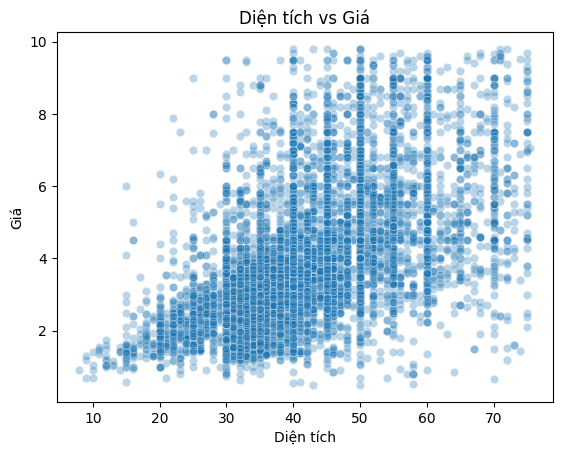

In [18]:
sns.scatterplot(data=df, x='Diện tích', y='Giá', alpha=0.3)
plt.title('Diện tích vs Giá')
plt.show()

## 5. Encoding & train/test split

In [19]:
df = df.drop(columns=['Dài', 'Rộng'])

In [20]:
vc = df['Quận'].value_counts()
rare = vc[vc < 30].index
print('Gộp:', list(rare))
df['Quận'] = df['Quận'].replace(rare, 'Khác')
df['Quận'].value_counts()

Gộp: ['Huyện Gia Lâm', 'Huyện Thanh Oai', 'Huyện Đông Anh', 'Thị xã Sơn Tây', 'Huyện Sóc Sơn', 'Huyện Chương Mỹ', 'Huyện Đan Phượng', 'Huyện Thường Tín']


,count
Quận,
Quận Hà Đông,1465
Quận Đống Đa,1356
Quận Thanh Xuân,1303
Quận Hoàng Mai,1158
Quận Hai Bà Trưng,927
Quận Cầu Giấy,894
Quận Long Biên,650
Quận Ba Đình,549
Quận Nam Từ Liêm,465


In [21]:
df['Có sổ'] = (df['Giấy tờ pháp lý'] == 'Đã có sổ').astype(int)
df = df.drop(columns=['Giấy tờ pháp lý'])

In [22]:
X = pd.get_dummies(df.drop(columns='Giá'),
                   columns=['Quận', 'Loại hình nhà ở'],
                   drop_first=True, dtype=int)
y = df['Giá']

print(X.shape)
X.columns.tolist()

(9862, 21)


['Số tầng',
 'Số phòng ngủ',
 'Diện tích',
 'Có sổ',
 'Quận_Huyện Thanh Trì',
 'Quận_Khác',
 'Quận_Quận Ba Đình',
 'Quận_Quận Bắc Từ Liêm',
 'Quận_Quận Cầu Giấy',
 'Quận_Quận Hai Bà Trưng',
 'Quận_Quận Hoàn Kiếm',
 'Quận_Quận Hoàng Mai',
 'Quận_Quận Hà Đông',
 'Quận_Quận Long Biên',
 'Quận_Quận Nam Từ Liêm',
 'Quận_Quận Thanh Xuân',
 'Quận_Quận Tây Hồ',
 'Quận_Quận Đống Đa',
 'Loại hình nhà ở_Nhà mặt phố, mặt tiền',
 'Loại hình nhà ở_Nhà ngõ, hẻm',
 'Loại hình nhà ở_Nhà phố liền kề']

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(7889, 21) (1973, 21)


In [24]:
print(sorted(df['Quận'].unique())[0])
print(sorted(df['Loại hình nhà ở'].unique())[0])


Huyện Hoài Đức
Nhà biệt thự


## 6. Model

In [25]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print('Intercept:', model.intercept_)

Intercept: -1.0977305508453252


Loại hình nhà ở_Nhà ngõ, hẻm            -1.645678
Quận_Khác                               -0.857763
Loại hình nhà ở_Nhà mặt phố, mặt tiền   -0.561721
Loại hình nhà ở_Nhà phố liền kề         -0.321821
Quận_Huyện Thanh Trì                    -0.075517
Số tầng                                  0.063728
Diện tích                                0.076073
Số phòng ngủ                             0.219588
Quận_Quận Hà Đông                        0.399249
Quận_Quận Bắc Từ Liêm                    0.562682
Quận_Quận Long Biên                      0.669200
Quận_Quận Hoàng Mai                      0.763500
Có sổ                                    0.911840
Quận_Quận Nam Từ Liêm                    0.976568
Quận_Quận Thanh Xuân                     1.371130
Quận_Quận Hai Bà Trưng                   1.374270
Quận_Quận Tây Hồ                         1.575275
Quận_Quận Đống Đa                        1.881883
Quận_Quận Ba Đình                        1.959053
Quận_Quận Cầu Giấy                       2.053126


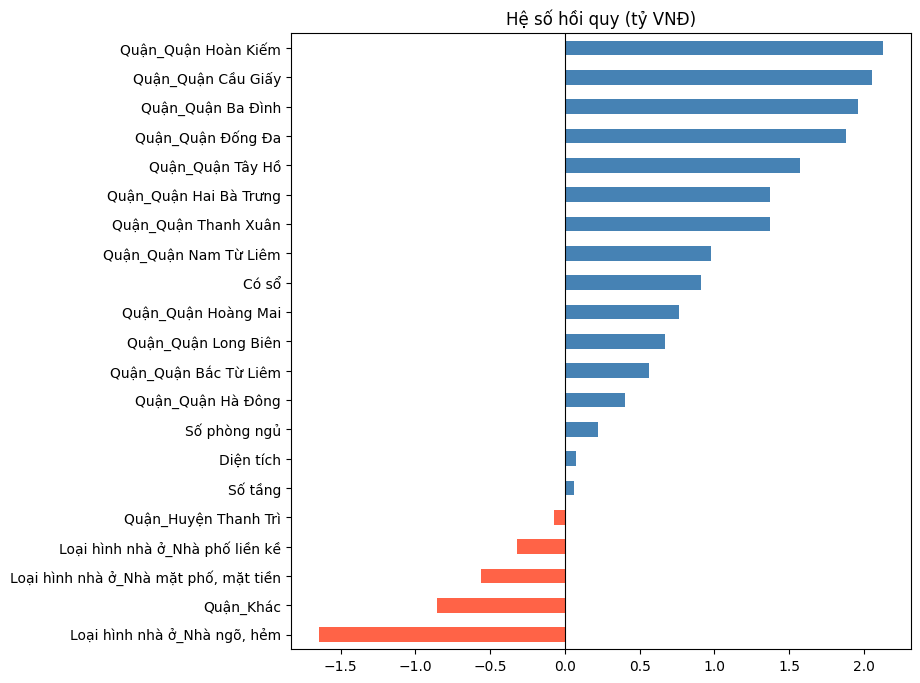

In [26]:
coef = pd.Series(model.coef_, index=X.columns).sort_values()
print(coef)

plt.figure(figsize=(8, 8))
coef.plot(kind='barh', color=['tomato' if c < 0 else 'steelblue' for c in coef])
plt.axvline(0, color='black', lw=0.8)
plt.title('Hệ số hồi quy (tỷ VNĐ)')
plt.show()

## 7. Evaluation

In [27]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

y_pred = model.predict(X_test)

print('R² train:', r2_score(y_train, model.predict(X_train)))
print('R² test :', r2_score(y_test, y_pred))
print('MAE     :', mean_absolute_error(y_test, y_pred))
print('RMSE    :', np.sqrt(mean_squared_error(y_test, y_pred)))

R² train: 0.5707390502331242
R² test : 0.5479347497145879
MAE     : 0.850488000739314
RMSE    : 1.1591473061070545


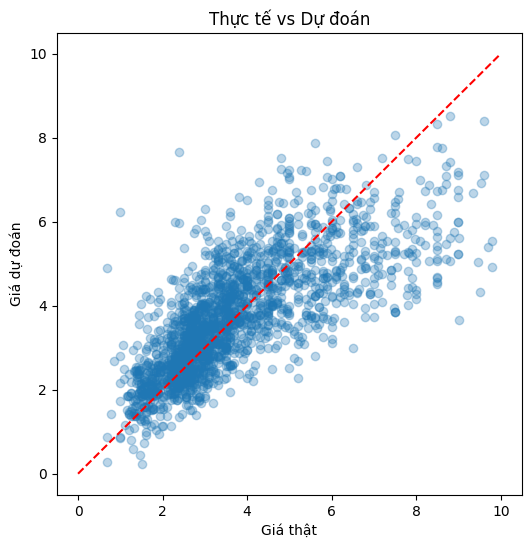

In [28]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([0, 10], [0, 10], 'r--')
plt.xlabel('Giá thật'); plt.ylabel('Giá dự đoán')
plt.title('Thực tế vs Dự đoán')
plt.show()

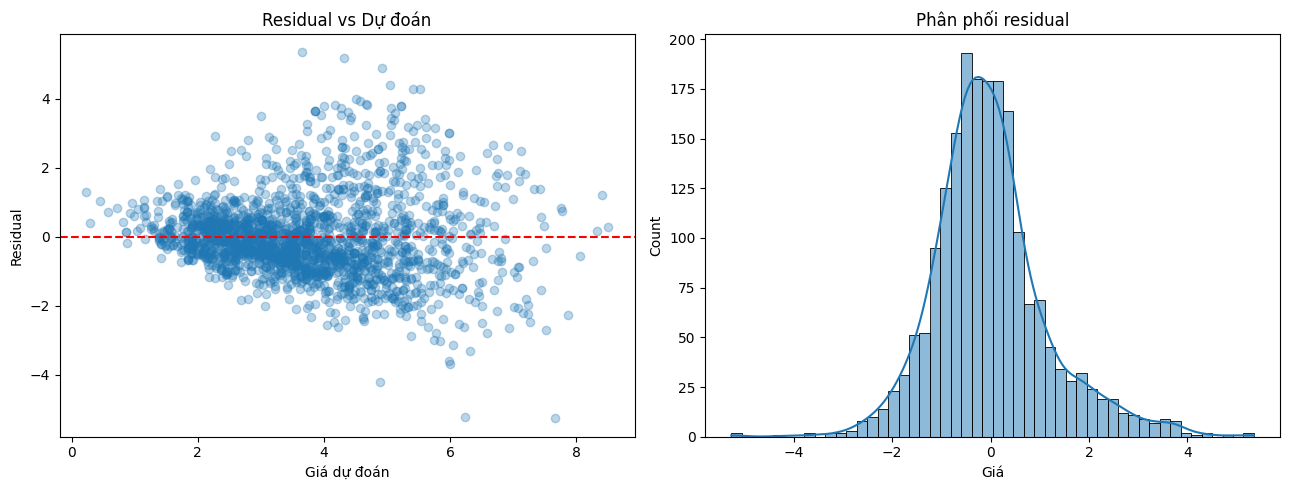

In [29]:
resid = y_test - y_pred

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_pred, resid, alpha=0.3)
ax[0].axhline(0, color='r', ls='--')
ax[0].set_xlabel('Giá dự đoán'); ax[0].set_ylabel('Residual')
ax[0].set_title('Residual vs Dự đoán')

sns.histplot(resid, bins=50, kde=True, ax=ax[1])
ax[1].set_title('Phân phối residual')
plt.tight_layout()
plt.show()

## 8. Statiscal tests

In [30]:
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                    Giá   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.570
Method:                 Least Squares   F-statistic:                     498.1
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:50:42   Log-Likelihood:                -12589.
No. Observations:                7889   AIC:                         2.522e+04
Df Residuals:                    7867   BIC:                         2.538e+04
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [31]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame({
    'Biến': X_train_sm.columns,
    'VIF': [variance_inflation_factor(X_train_sm.values, i)
            for i in range(X_train_sm.shape[1])]
})
vif[vif['Biến'].isin(['Diện tích', 'Số tầng', 'Số phòng ngủ'])]

,Biến,VIF
1,Số tầng,1.132503
2,Số phòng ngủ,1.327362
3,Diện tích,1.252092


## 9. Prediction example

In [32]:
def du_doan(dien_tich, so_tang, so_phong, quan, loai_hinh, co_so=1):
    x = pd.DataFrame(0, index=[0], columns=X.columns)
    x['Diện tích'] = dien_tich
    x['Số tầng'] = so_tang
    x['Số phòng ngủ'] = so_phong
    x['Có sổ'] = co_so
    if f'Quận_{quan}' in x.columns:
        x[f'Quận_{quan}'] = 1
    if f'Loại hình nhà ở_{loai_hinh}' in x.columns:
        x[f'Loại hình nhà ở_{loai_hinh}'] = 1
    return model.predict(x)[0]

gia = du_doan(40, 4, 3, 'Quận Cầu Giấy', 'Nhà ngõ, hẻm')
print(f'Giá dự đoán: {gia:.2f} tỷ')

Giá dự đoán: 4.18 tỷ


## 10. Adding ward (Model 2)

In [33]:
raw = pd.read_csv(DATA_PATH)
df['Phường'] = raw.loc[df.index, 'Phường']

# Ghép tên phường với tên quận, vì có những phường trùng tên ở các quận khác nhau
df['PQ'] = df['Phường'] + ' - ' + raw.loc[df.index, 'Quận']
print('Số phường:', df['PQ'].nunique())

Số phường: 207


In [34]:
vc = df.loc[X_train.index, 'PQ'].value_counts()
keep = vc[vc >= 30].index
df['PQ'] = df['PQ'].where(df['PQ'].isin(keep), 'Khác')
print('Giữ lại:', df['PQ'].nunique(), 'nhóm')

Giữ lại: 95 nhóm


In [35]:
X2 = pd.concat([X, pd.get_dummies(df['PQ'], prefix='P', drop_first=True, dtype=int)], axis=1)
X2_train, X2_test = X2.loc[X_train.index], X2.loc[X_test.index]
print(X2.shape)

model2 = LinearRegression().fit(X2_train, y_train)
y_pred2 = model2.predict(X2_test)

(9862, 115)


In [36]:
def danh_gia(m, Xtr, Xte):
    return {'R² train': r2_score(y_train, m.predict(Xtr)),
            'R² test':  r2_score(y_test, m.predict(Xte)),
            'MAE':      mean_absolute_error(y_test, m.predict(Xte)),
            'RMSE':     np.sqrt(mean_squared_error(y_test, m.predict(Xte))),
            'Số biến':  Xtr.shape[1]}

pd.DataFrame({'Model 1 (Quận)':  danh_gia(model,  X_train,  X_test),
              'Model 2 (+Phường)': danh_gia(model2, X2_train, X2_test)}).round(3)

,Model 1 (Quận),Model 2 (+Phường)
R² train,0.571,0.610
R² test,0.548,0.576
MAE,0.850,0.814
RMSE,1.159,1.123
Số biến,21.000,115.000


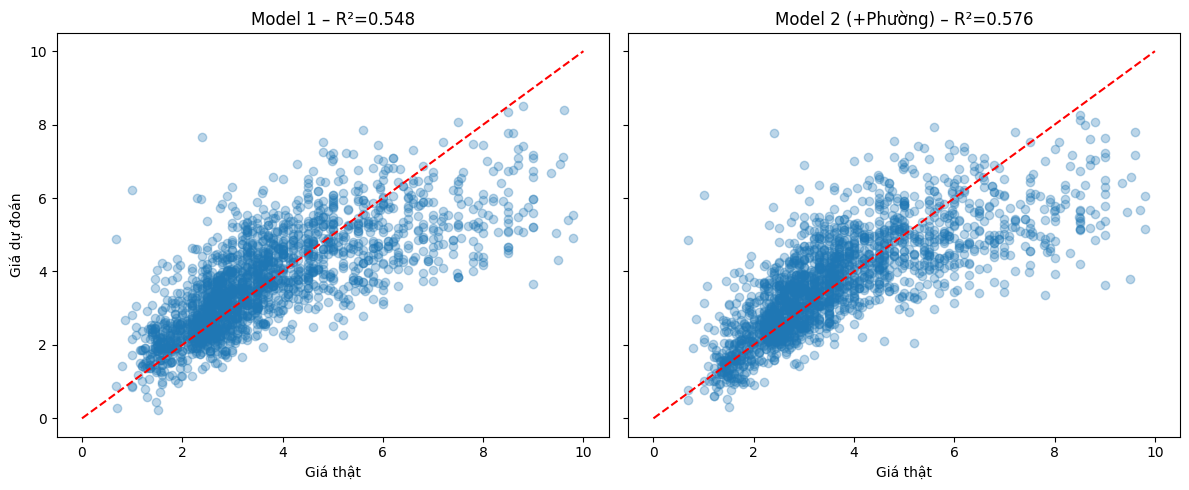

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for a, yp, t in zip(ax, [y_pred, y_pred2], ['Model 1', 'Model 2 (+Phường)']):
    a.scatter(y_test, yp, alpha=0.3)
    a.plot([0, 10], [0, 10], 'r--')
    a.set_title(f'{t} – R²={r2_score(y_test, yp):.3f}')
    a.set_xlabel('Giá thật')
ax[0].set_ylabel('Giá dự đoán')
plt.tight_layout()
plt.show()

In [38]:
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
for ten, XX in [('Model 1', X), ('Model 2', X2)]:
    s = cross_val_score(LinearRegression(), XX, y, cv=kf, scoring='r2')
    print(f'{ten}: {s.round(3)}  →  TB = {s.mean():.3f} ± {s.std():.3f}')

Model 1: [0.548 0.562 0.575 0.554 0.573]  →  TB = 0.562 ± 0.011
Model 2: [0.576 0.593 0.604 0.587 0.603]  →  TB = 0.592 ± 0.010


## 11.  Kết luận

### 1. Tóm tắt kết quả
- Dữ liệu: 11.294 tin rao bán nhà tại Hà Nội (07–08/2020). Sau khi làm sạch và loại outlier còn 9.862 căn (nhà ≤ 75 m², giá 0.5–9.85 tỷ).
- **Model 1** (diện tích, số tầng, số phòng ngủ, pháp lý, quận, loại hình; 21 biến): R² test = **0.548**, MAE = **0.85 tỷ**.
- **Model 2** (thêm phường; 115 biến): R² test = **0.576**, MAE = **0.81 tỷ**. 5-fold CV: 0.592 ± 0.010 so với 0.562 ± 0.011. Model 2 tốt hơn ở cả 5 fold.
- Mô hình giải thích được khoảng **55–58%** biến động giá; trung bình dự đoán lệch khoảng **810–850 triệu**/căn.
- Không có overfitting đáng kể (train–test chênh 2–3 điểm), không có đa cộng tuyến (VIF < 1.4).

### 2. Các yếu tố ảnh hưởng đến giá
1. **Vị trí (quận) là yếu tố mạnh nhất.** Cùng diện tích và đặc điểm, nhà ở Hoàn Kiếm, Cầu Giấy, Ba Đình đắt hơn Hoài Đức khoảng **2 tỷ**.
2. **Loại hình:** nhà trong ngõ/hẻm rẻ hơn biệt thự khoảng 1.65 tỷ, rẻ hơn nhà mặt phố khoảng 1.1 tỷ.
3. **Diện tích:** mỗi m² tăng thêm làm giá tăng khoảng **76 triệu** (t = 57.5, biến có ý nghĩa thống kê mạnh nhất).
4. **Pháp lý:** nhà đã có sổ đắt hơn khoảng **0.9 tỷ**.
5. Số phòng ngủ (+0.22 tỷ/phòng) và số tầng (+0.06 tỷ/tầng) ảnh hưởng nhỏ hơn.

**Phát hiện đáng chú ý:** xét theo giá trung vị, Cầu Giấy (4.55 tỷ) đắt hơn Hoàn Kiếm (3.93 tỷ). Nhưng nhà ở Hoàn Kiếm nhỏ hơn hẳn (34.5 so với 44 m²). Khi kiểm soát diện tích, **Hoàn Kiếm lại là quận đắt nhất**. So sánh trung bình đơn thuần có thể dẫn đến kết luận sai; hồi quy bội tách được tác động riêng của từng yếu tố.

### 3. Hạn chế
- **Chất lượng dữ liệu:** dữ liệu là tin rao, nên có lỗi nhập liệu (giá = 0, chiều dài nhập theo mm, ví dụ "120000 m"), diện tích bị làm tròn. Đây là **giá rao bán**, không phải giá giao dịch thực.
- **Vi phạm giả định:** residual có phương sai không đồng nhất (Breusch–Pagan p ≈ 0) và lệch phải (Jarque–Bera p ≈ 0). p-value thông thường có thể quá lạc quan.
- **Sai lệch có hệ thống:** nhà giá > 7 tỷ bị dự đoán thấp trung bình khoảng 2.5 tỷ.
- **Phạm vi áp dụng hẹp:** chỉ đúng cho nhà ≤ 75 m², giá ≤ 10 tỷ. Không áp dụng cho biệt thự lớn, nhà mặt phố cao cấp, căn hộ chung cư.
- **Thời điểm:** dữ liệu năm 2020, trước đợt tăng giá mạnh 2021–2024, nên không dùng trực tiếp để định giá hiện nay.
- **Thiếu biến quan trọng:** khoảng 42% biến động chưa được giải thích, nhiều khả năng do thiếu độ rộng ngõ, khoảng cách tới đường lớn, nội thất, hướng, tuổi nhà.

### 4. Hướng phát triển
- Bổ sung đặc trưng vị trí: độ rộng ngõ, khoảng cách tới trung tâm/đường lớn (geocoding từ địa chỉ).
- Thử các mô hình phi tuyến (Random Forest, Gradient Boosting) để bắt các tương tác như "diện tích × quận".
- Dùng robust standard error (HC3) hoặc hồi quy có trọng số để xử lý heteroscedasticity.
- Cập nhật dữ liệu mới hơn để so sánh biến động giá theo thời gian.

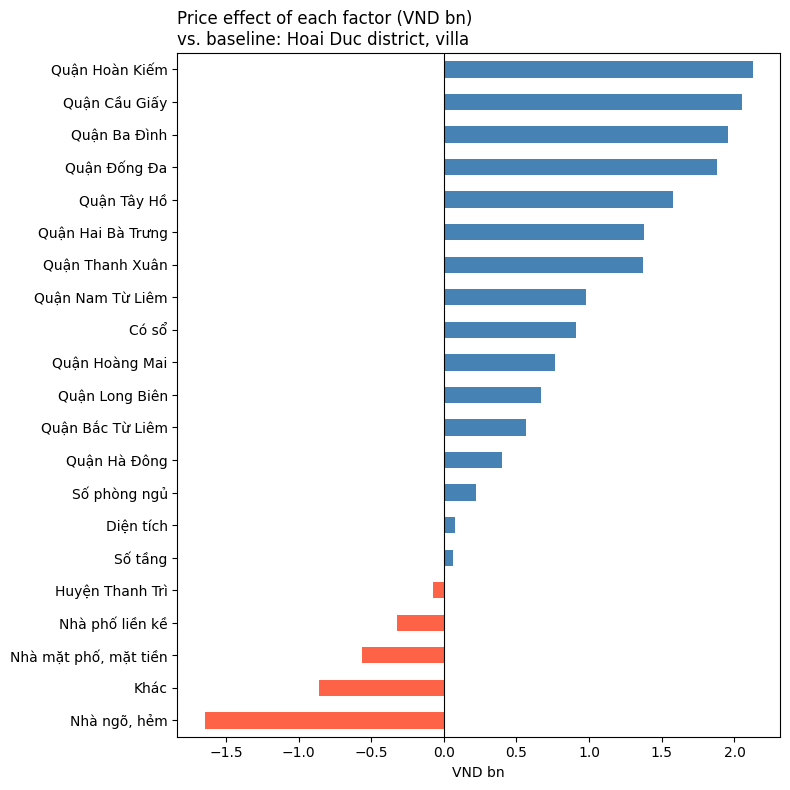

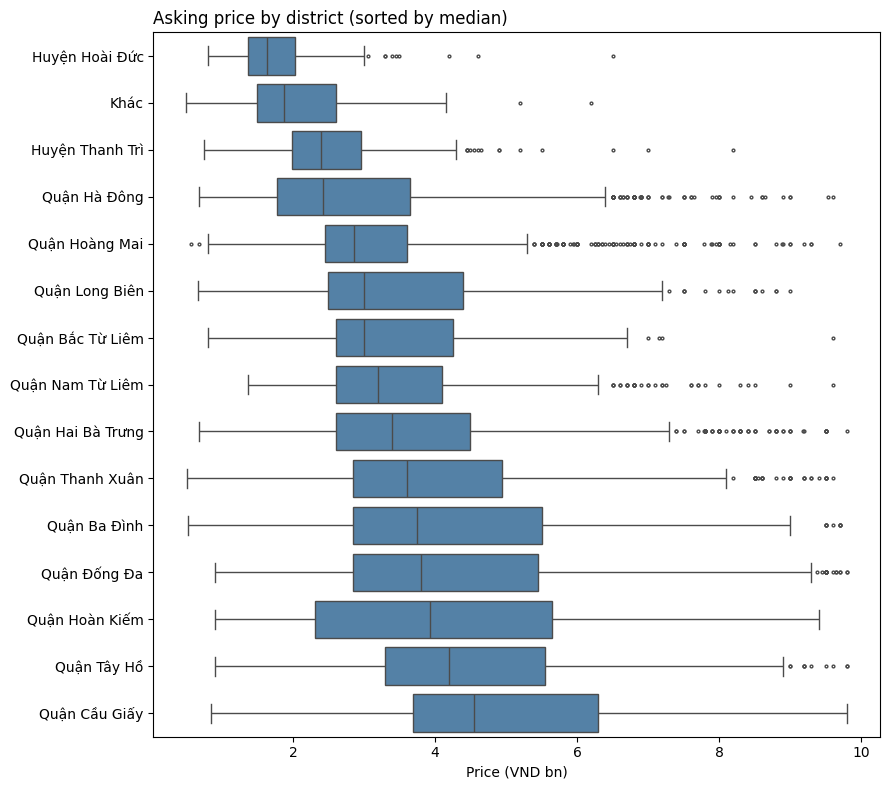

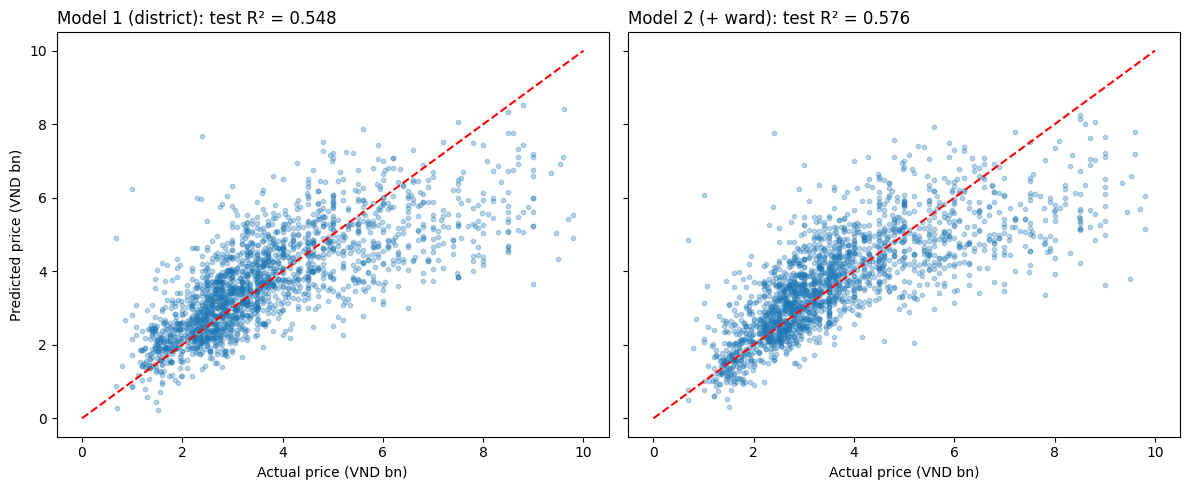

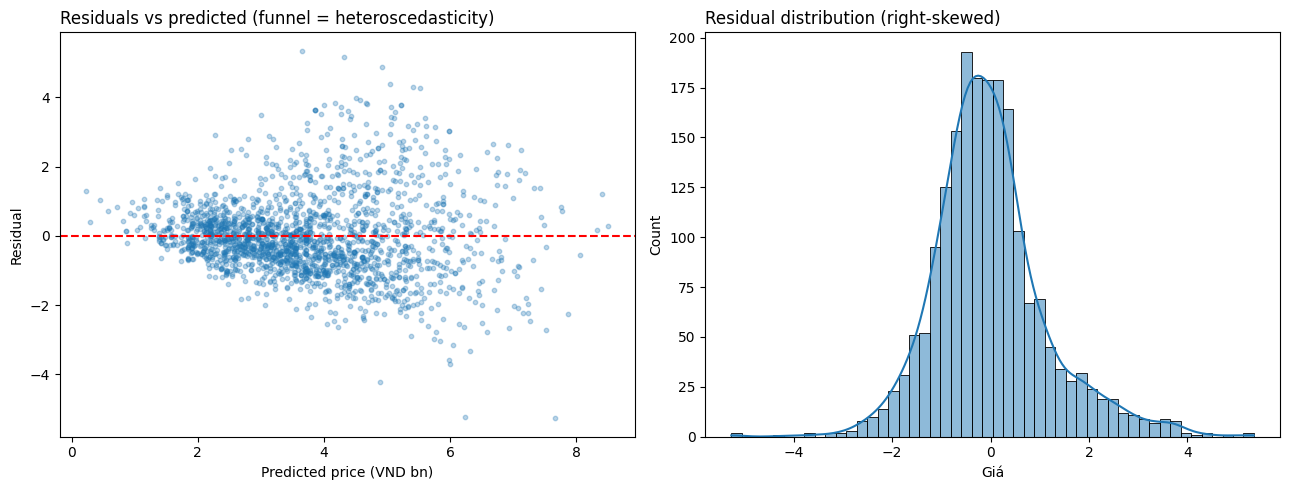

['02_price_by_district.png', '03_actual_vs_predicted.png', '01_coefficients.png', '04_residuals.png']


In [39]:
# ===== Xuất biểu đồ cho README =====
import os
os.makedirs('images', exist_ok=True)

# 1. Hệ số hồi quy: yếu tố nào đẩy giá lên / kéo giá xuống
coef_plot = coef.rename(lambda s: s.replace('Quận_', '').replace('Loại hình nhà ở_', ''))
fig, ax = plt.subplots(figsize=(8, 8))
coef_plot.plot(kind='barh', ax=ax, color=['tomato' if c < 0 else 'steelblue' for c in coef_plot])
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Price effect of each factor (VND bn)\nvs. baseline: Hoai Duc district, villa', loc='left')
ax.set_xlabel('VND bn')
plt.tight_layout(); plt.savefig('images/01_coefficients.png', dpi=150); plt.show()

# 2. Giá theo quận
order = df.groupby('Quận')['Giá'].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 8))
sns.boxplot(data=df, y='Quận', x='Giá', order=order, ax=ax, color='steelblue', fliersize=2)
ax.set_title('Asking price by district (sorted by median)', loc='left')
ax.set_xlabel('Price (VND bn)'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('images/02_price_by_district.png', dpi=150); plt.show()

# 3. Thực tế vs dự đoán: Model 1 vs Model 2
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for a, yp, t in zip(axes, [y_pred, y_pred2], ['Model 1 (district)', 'Model 2 (+ ward)']):
    a.scatter(y_test, yp, alpha=0.3, s=10)
    a.plot([0, 10], [0, 10], 'r--')
    a.set_title(f'{t}: test R² = {r2_score(y_test, yp):.3f}', loc='left')
    a.set_xlabel('Actual price (VND bn)')
axes[0].set_ylabel('Predicted price (VND bn)')
plt.tight_layout(); plt.savefig('images/03_actual_vs_predicted.png', dpi=150); plt.show()

# 4. Residual: kiểm tra giả định
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_pred, resid, alpha=0.3, s=10)
axes[0].axhline(0, color='r', ls='--')
axes[0].set_title('Residuals vs predicted (funnel = heteroscedasticity)', loc='left')
axes[0].set_xlabel('Predicted price (VND bn)'); axes[0].set_ylabel('Residual')
sns.histplot(resid, bins=50, kde=True, ax=axes[1])
axes[1].set_title('Residual distribution (right-skewed)', loc='left')
plt.tight_layout(); plt.savefig('images/04_residuals.png', dpi=150); plt.show()

print(os.listdir('images'))

In [40]:
!zip -r images.zip images
from google.colab import files
files.download('images.zip')

  adding: images/ (stored 0%)
  adding: images/02_price_by_district.png (deflated 22%)
  adding: images/03_actual_vs_predicted.png (deflated 3%)
  adding: images/01_coefficients.png (deflated 23%)
  adding: images/04_residuals.png (deflated 5%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>